# T2: frozen SMARTS dev sets and holdout, figures

Regenerates every README figure. The heavy lifting is in `tools/build_dev_sets.py`,
`make_data.py` and the scorecard runs; see the README's "Reproduce" section.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.simplefilter("ignore")
ROOT = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(ROOT / "claude_files")); sys.path.insert(0, str(ROOT / "tools"))
import coverage as cov, evaluation as ev
import build_dev_sets as bds
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
D = Path("data"); DS = ROOT / "datasets"; BL = ROOT / "benchmarks" / "baselines"
SETS = {n: pd.read_csv(DS / f"{n}.csv", dtype={"sectors": str, "native_sectors": str, "native_whole_sectors": str})
        for n in bds.SET_ORDER}
counts = pd.read_csv(DS / "strata_counts.csv")
excl = pd.read_csv(DS / "exclusions_log.csv")
PB = list(bds.AUDIT_PBIN_LABELS); CLS = list(cov.COVERAGE_CLASSES); EB = list(ev.PERIOD_BIN_LABELS)
C1, C2, C3, C4, GRAY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#4a3aa7", "#9c9a92", "#52514e"
OUT_COL = {"success": C3, "alias": C4, "wrong": C2, "none": GRAY}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "font.size": 9,
                     "savefig.dpi": 130, "savefig.bbox": "tight"})

## 1. Stratum counts

Rows: audit period bin. Columns: amplitude tercile × shear class. dev_small has 50 rows for
63 strata, so it has about one star per cell below 60 d and 7 stars in total above 60 d. In the
holdout's <1 d row, cells are uneven because that bin's pool is small (984 rows, 803 checked).

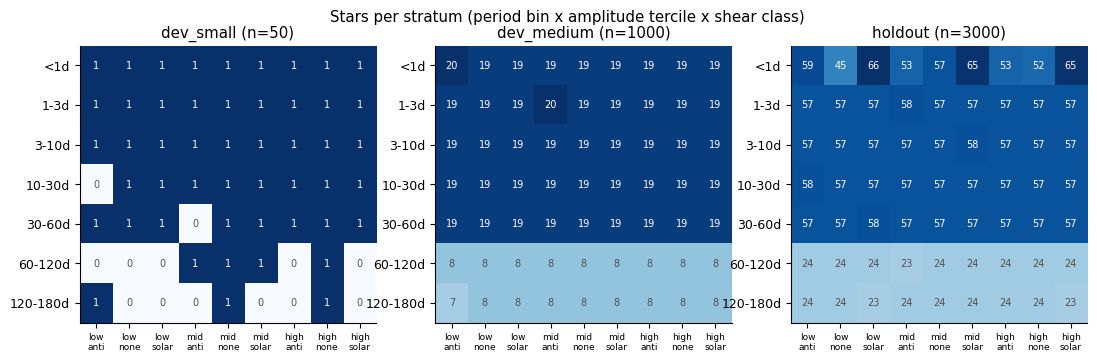

,dev_small,dev_medium,holdout,pool,pool share
pbin,,,,,
<1d,9,172,515,984,0.0049
1-3d,9,172,514,2247,0.0112
3-10d,9,171,514,7872,0.0394
10-30d,8,171,514,22285,0.1114
30-60d,8,171,514,33335,0.1667
60-120d,4,72,215,66638,0.3332
120-180d,3,71,214,66639,0.3332


In [2]:
cells_ = [f"{a}|{s}" for a, s in bds.CELLS]
fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, name in zip(axs, bds.SET_ORDER):
    t = counts.assign(cell=counts.amp_tier + "|" + counts.shear_class).pivot(index="pbin", columns="cell", values=f"n_{name}").loc[PB, cells_]
    ax.imshow(t.values, cmap="Blues", aspect="auto", vmin=0)
    for i in range(t.shape[0]):
        for j in range(t.shape[1]):
            ax.text(j, i, int(t.values[i, j]), ha="center", va="center", fontsize=7,
                    color="white" if t.values[i, j] > 0.6 * t.values.max() else INK)
    ax.set_xticks(range(9), [c.replace("|", "\n") for c in cells_], fontsize=6.5)
    ax.set_yticks(range(7), PB); ax.grid(False)
    ax.set_title(f"{name} (n={len(SETS[name])})")
fig.suptitle("Stars per stratum (period bin x amplitude tercile x shear class)")
fig.savefig(FIG / "fig_strata_counts.png"); plt.show()
tab = pd.DataFrame({n: SETS[n].pbin.value_counts().reindex(PB) for n in bds.SET_ORDER})
tab["pool"] = counts.groupby("pbin").n_pool.sum().reindex(PB)
tab["pool share"] = (tab["pool"] / tab["pool"].sum()).round(4)
tab

## 2. Distributions vs the corpus

The period distribution is deliberately skewed: the corpus is uniform in P, while the sets
are equal-per-bin in log P. Weighting by `sampling_weight` recovers the pool distribution
(dashed). The other parameters should match the pool, apart from small-number noise in
dev_small.

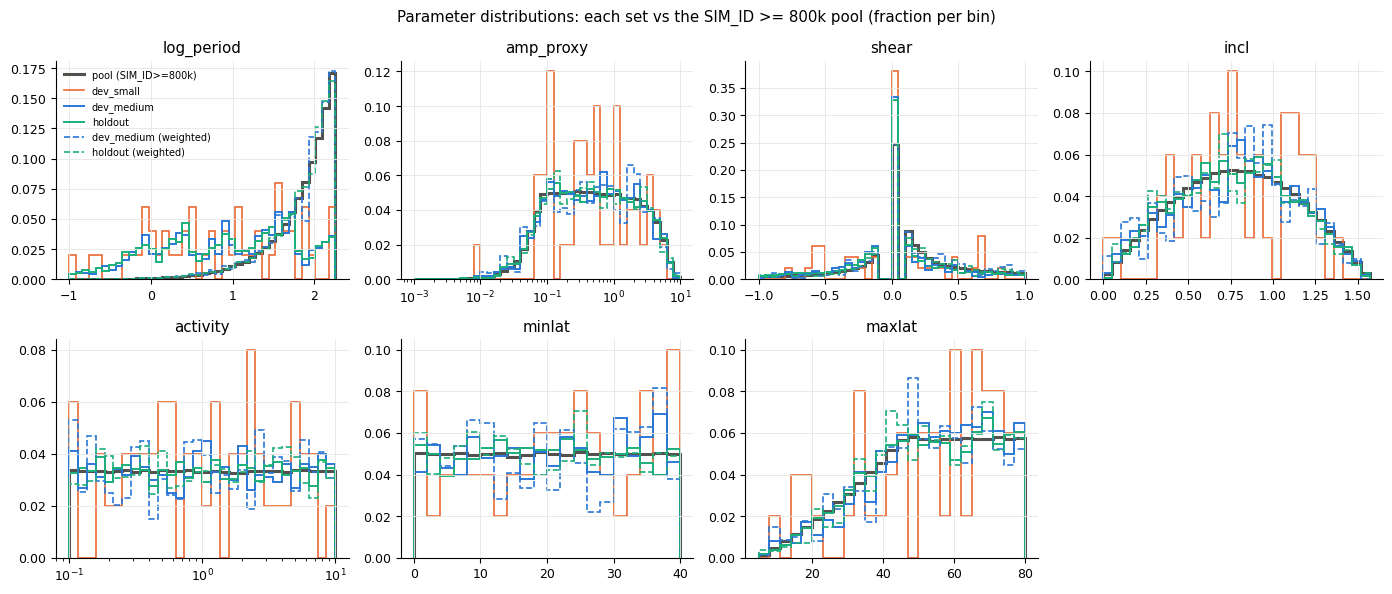

In [3]:
H = pd.concat([pd.read_csv(D / "corpus_hists.csv"), pd.read_csv(D / "set_hists.csv")])
params = ["log_period", "amp_proxy", "shear", "incl", "activity", "minlat", "maxlat"]
fig, axs = plt.subplots(2, 4, figsize=(14, 6)); axs = axs.ravel()
style = {"pool (SIM_ID>=800k)": dict(color=INK, lw=2.2),
         "dev_small": dict(color=C2, lw=1.2), "dev_medium": dict(color=C1, lw=1.4), "holdout": dict(color=C3, lw=1.4),
         "dev_medium (weighted)": dict(color=C1, lw=1.2, ls="--"), "holdout (weighted)": dict(color=C3, lw=1.2, ls="--")}
for ax, p in zip(axs, params):
    for lab, kw in style.items():
        h = H[(H.set == lab) & (H.param == p)]
        x = np.r_[h.lo.values, h.hi.values[-1]]
        ax.stairs(h.frac.values, x, label=lab, **kw)
    ax.set_title(p); ax.set_xscale("log" if p in ("amp_proxy", "activity") else "linear")
axs[-1].axis("off"); axs[0].legend(fontsize=7, loc="upper left", frameon=False)
fig.suptitle("Parameter distributions: each set vs the SIM_ID >= 800k pool (fraction per bin)")
fig.tight_layout(); fig.savefig(FIG / "fig_distributions.png"); plt.show()

## 3. Coverage-class mix

Classes are balanced in every set (left), whereas real TESS star-seasons are 66% single
sector (pooled library, gray). `coverage_weight` reweights to the real mix. Right: dev_medium
classes per period bin, showing the balance holds within every bin.

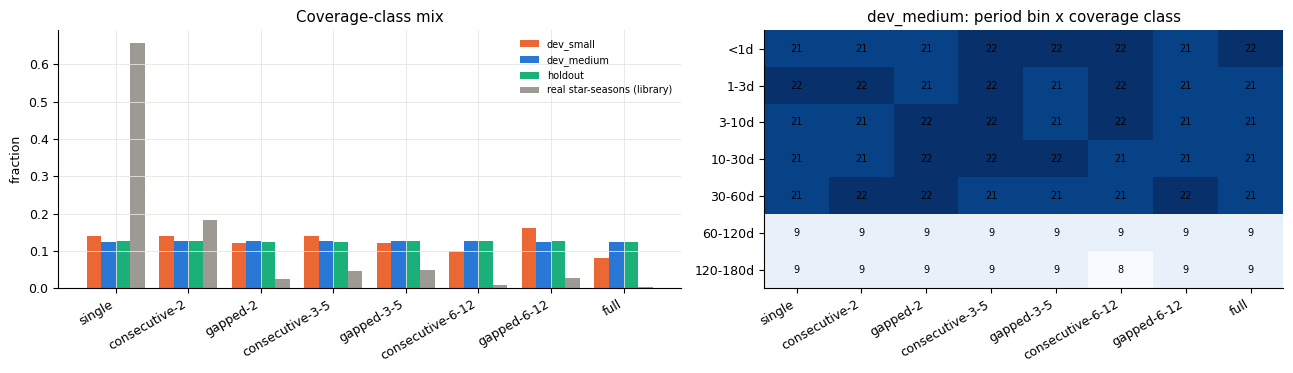

,real,dev_small,dev_medium,holdout
single,0.658,7,124,376
consecutive-2,0.183,7,125,375
gapped-2,0.024,6,126,374
consecutive-3-5,0.046,7,127,373
gapped-3-5,0.048,6,125,376
consecutive-6-12,0.008,5,125,378
gapped-6-12,0.028,8,124,375
full,0.004,4,124,373


In [4]:
lib = cov.load_library()
real = lib.groupby("class").n_stars.sum().reindex(CLS) / lib.n_stars.sum()
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1.2, 1]})
w = 0.2
for k, (name, col) in enumerate(zip(bds.SET_ORDER, [C2, C1, C3])):
    f = SETS[name].coverage_class.value_counts(normalize=True).reindex(CLS).fillna(0)
    a.bar(np.arange(8) + (k - 1.5) * w, f, w, color=col, label=name)
a.bar(np.arange(8) + 1.5 * w, real, w, color=GRAY, label="real star-seasons (library)")
a.set_xticks(range(8), CLS, rotation=30, ha="right"); a.set_ylabel("fraction"); a.legend(fontsize=7, frameon=False)
a.set_title("Coverage-class mix")
t = pd.crosstab(SETS["dev_medium"].pbin, SETS["dev_medium"].coverage_class).reindex(index=PB, columns=CLS)
b.imshow(t.values, cmap="Blues", aspect="auto"); b.grid(False)
for i in range(t.shape[0]):
    for j in range(t.shape[1]):
        b.text(j, i, t.values[i, j], ha="center", va="center", fontsize=7)
b.set_xticks(range(8), CLS, rotation=30, ha="right"); b.set_yticks(range(7), PB); b.set_title("dev_medium: period bin x coverage class")
fig.tight_layout(); fig.savefig(FIG / "fig_coverage_mix.png"); plt.show()
pd.DataFrame({"real": real.round(3), **{n: SETS[n].coverage_class.value_counts().reindex(CLS) for n in bds.SET_ORDER}})

Native coverage before any pattern is applied: the whole-sector counts limit which
patterns a file can take (`full` needs all 13).

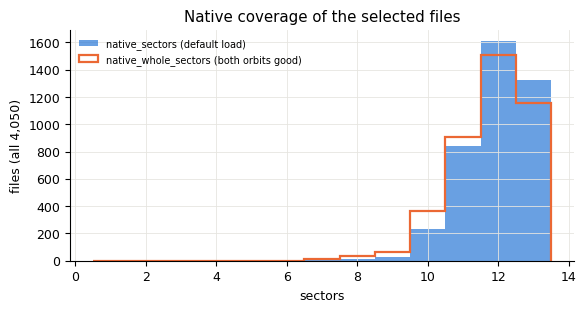

13 native: 0.326  13 whole: 0.286  rows where whole < native: 0.156


In [5]:
fig, ax = plt.subplots(figsize=(6.5, 3))
allm = pd.concat(SETS.values())
bins = np.arange(0.5, 14.5)
ax.hist(allm.n_native_sectors, bins, color=C1, alpha=0.7, label="native_sectors (default load)")
ax.hist(allm.n_whole_sectors, bins, histtype="step", color=C2, lw=1.6, label="native_whole_sectors (both orbits good)")
ax.set_xlabel("sectors"); ax.set_ylabel("files (all 4,050)"); ax.legend(fontsize=7, frameon=False)
ax.set_title("Native coverage of the selected files")
fig.savefig(FIG / "fig_native_sectors.png"); plt.show()
print("13 native:", (allm.n_native_sectors == 13).mean().round(3), " 13 whole:", (allm.n_whole_sectors == 13).mean().round(3),
      " rows where whole < native:", (allm.n_whole_sectors < allm.n_native_sectors).mean().round(3))

## 4. Exclusions

All exclusions are corrupt galaxy noise (raw max |flux − 1| > 0.1). The rate is similar across
period bins, as expected for a galaxy-noise property.

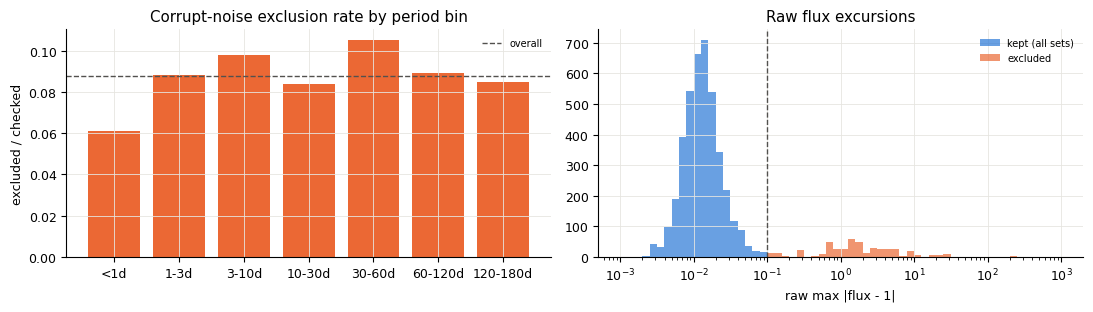

,n_checked,n_excluded,rate
pbin,,,
<1d,803,49,0.061
1-3d,911,80,0.088
3-10d,910,89,0.098
10-30d,909,76,0.084
30-60d,908,95,0.105
60-120d,381,34,0.089
120-180d,378,32,0.085


In [6]:
c = counts.groupby("pbin")[["n_checked", "n_excluded"]].sum().reindex(PB)
c["rate"] = (c.n_excluded / c.n_checked).round(3)
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.2))
a.bar(PB, c.rate, color=C2); a.axhline(c.n_excluded.sum() / c.n_checked.sum(), color=INK, ls="--", lw=1, label="overall")
a.set_ylabel("excluded / checked"); a.set_title("Corrupt-noise exclusion rate by period bin"); a.legend(frameon=False, fontsize=7)
edges = np.geomspace(1e-3, 1e3, 61)
b.hist(allm.max_abs_dev, edges, color=C1, alpha=0.7, label="kept (all sets)")
b.hist(excl.max_abs_dev, edges, color=C2, alpha=0.7, label="excluded")
b.axvline(bds.CORRUPT_THRESH, color=INK, ls="--", lw=1); b.set_xscale("log"); b.set_xlabel("raw max |flux - 1|")
b.legend(frameon=False, fontsize=7); b.set_title("Raw flux excursions")
fig.tight_layout(); fig.savefig(FIG / "fig_exclusions.png"); plt.show()
c

## 5. Headline: the pipeline on real SMARTS noise vs the synthetic baseline

Final-answer outcomes, by period bin (`evaluation.period_bin`), for:
- the synthetic baseline (synth200 seed 0, full year);
- dev_medium (and dev_small), full-year and with their assigned coverage.

Same scorecard, same pipeline commit.

In [7]:
def tables(name):
    return pd.read_csv(BL / f"{name}_tables" / "per_star.csv")
RUNS = {"synth200 (full year)": tables("synth200_s0"),
        "dev_small full year": tables("dev_small_fullyear"), "dev_small assigned": tables("dev_small_assigned"),
        "dev_medium full year": tables("dev_medium_fullyear"), "dev_medium assigned": tables("dev_medium_assigned")}
def frac(df, by):
    o = df.final_outcome.replace({"correct": "success", "diffrot": "success", "half": "alias", "double": "alias"})
    return pd.crosstab(df[by], o, normalize="index").reindex(columns=["success", "alias", "wrong", "none"], fill_value=0)
summary = pd.DataFrame({k: frac(v.assign(all="all"), "all").iloc[0] for k, v in RUNS.items()}).T
summary["n"] = [len(v) for v in RUNS.values()]
summary.round(3)

final_outcome,success,alias,wrong,none,n
synth200 (full year),0.730,0.000,0.000,0.270,200
dev_small full year,0.260,0.020,0.040,0.680,50
dev_small assigned,0.160,0.020,0.040,0.780,50
dev_medium full year,0.248,0.014,0.088,0.650,1000
dev_medium assigned,0.148,0.009,0.054,0.789,1000


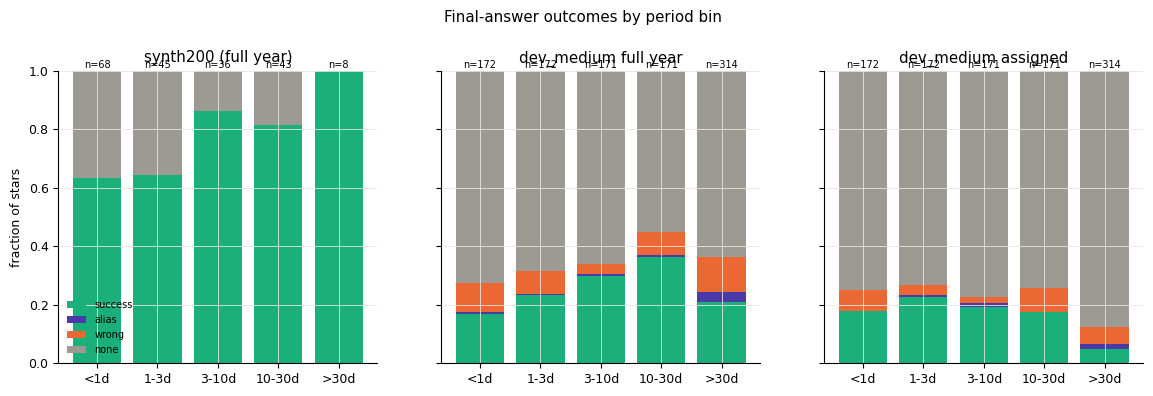

,synth200 (full year),dev_small full year,dev_small assigned,dev_medium full year,dev_medium assigned
period_bin,,,,,
<1d,0.632,0.222,0.222,0.169,0.180
1-3d,0.644,0.333,0.222,0.233,0.227
3-10d,0.861,0.222,0.333,0.298,0.193
10-30d,0.814,0.375,0.125,0.363,0.175
>30d,1.000,0.200,0.000,0.210,0.048


In [8]:
show = ["synth200 (full year)", "dev_medium full year", "dev_medium assigned"]
fig, axs = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, k in zip(axs, show):
    f = frac(RUNS[k], "period_bin").reindex(EB)
    bottom = np.zeros(len(EB))
    for o in ["success", "alias", "wrong", "none"]:
        ax.bar(EB, f[o], bottom=bottom, color=OUT_COL[o], label=o); bottom += f[o].values
    n = RUNS[k].period_bin.value_counts().reindex(EB)
    for i, v in enumerate(n):
        ax.text(i, 1.01, f"n={v}", ha="center", fontsize=7)
    ax.set_title(k)
axs[0].set_ylabel("fraction of stars"); axs[0].legend(fontsize=7, frameon=False, loc="lower left")
fig.suptitle("Final-answer outcomes by period bin", y=1.04)
fig.savefig(FIG / "fig_headline_by_bin.png"); plt.show()
pd.concat({k: frac(RUNS[k], "period_bin").reindex(EB)["success"] for k in RUNS}, axis=1).round(3)

By coverage class: the same 1,000 dev_medium stars, scored with their assigned pattern
and with the full year (paired). The full-year bars differ between classes only because of
the class's stars, not their coverage.

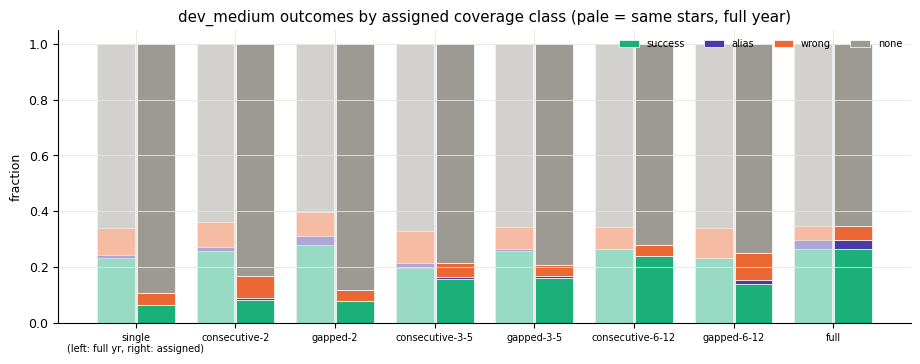

,success full yr,success assigned,wrong full yr,wrong assigned,none assigned
coverage_class,,,,,
single,0.234,0.065,0.097,0.040,0.895
consecutive-2,0.256,0.080,0.088,0.080,0.832
gapped-2,0.278,0.079,0.087,0.040,0.881
consecutive-3-5,0.197,0.157,0.118,0.047,0.787
gapped-3-5,0.256,0.160,0.080,0.040,0.792
consecutive-6-12,0.264,0.240,0.080,0.040,0.720
gapped-6-12,0.234,0.137,0.105,0.097,0.750
full,0.266,0.266,0.048,0.048,0.653


In [9]:
a = RUNS["dev_medium assigned"]; f = RUNS["dev_medium full year"]
man = SETS["dev_medium"][["star_id", "coverage_class", "sampling_weight", "coverage_weight", "combined_weight", "pbin"]]
pa = a[["star_id", "final_outcome"]].merge(man, on="star_id"); pf = f[["star_id", "final_outcome"]].merge(man, on="star_id")
sa, sf = frac(pa, "coverage_class").reindex(CLS), frac(pf, "coverage_class").reindex(CLS)
fig, ax = plt.subplots(figsize=(11, 3.8))
x = np.arange(8)
for off, s, lab in [(-0.2, sf, "full year"), (0.2, sa, "assigned coverage")]:
    bottom = np.zeros(8)
    for o in ["success", "alias", "wrong", "none"]:
        ax.bar(x + off, s[o], 0.38, bottom=bottom, color=OUT_COL[o], alpha=1 if off > 0 else 0.45,
               label=o if off > 0 else None, edgecolor="white", lw=0.5); bottom += s[o].values
ax.set_xticks(x, [f"{c}\n(left: full yr, right: assigned)" if i == 0 else c for i, c in enumerate(CLS)], fontsize=7, rotation=0)
ax.set_ylabel("fraction"); ax.legend(fontsize=7, frameon=False, ncol=4, loc="upper right")
ax.set_title("dev_medium outcomes by assigned coverage class (pale = same stars, full year)")
fig.savefig(FIG / "fig_headline_by_class.png"); plt.show()
pd.DataFrame({"success full yr": sf.success, "success assigned": sa.success,
              "wrong full yr": sf.wrong, "wrong assigned": sa.wrong, "none assigned": sa.none}).round(3)

Population-level estimates: the stratified rates reweighted to the corpus pool
(`sampling_weight`), and also to the real coverage mix (`combined_weight`).

In [10]:
def wrate(p, wcol):
    o = p.final_outcome.replace({"correct": "success", "diffrot": "success", "half": "alias", "double": "alias"})
    return pd.Series({k: float(np.average(o == k, weights=p[wcol])) for k in ["success", "alias", "wrong", "none"]})
est = pd.DataFrame({
    "full year, unweighted": wrate(pf.assign(u=1.0), "u"),
    "full year, corpus-weighted": wrate(pf, "sampling_weight"),
    "assigned, unweighted": wrate(pa.assign(u=1.0), "u"),
    "assigned, corpus-weighted": wrate(pa, "sampling_weight"),
    "assigned, corpus + real coverage mix": wrate(pa, "combined_weight")}).T
est.round(3)

,success,alias,wrong,none
"full year, unweighted",0.248,0.014,0.088,0.650
"full year, corpus-weighted",0.134,0.029,0.147,0.691
"assigned, unweighted",0.148,0.009,0.054,0.789
"assigned, corpus-weighted",0.045,0.014,0.063,0.878
"assigned, corpus + real coverage mix",0.012,0.001,0.042,0.944


By amplitude tercile (dev_medium, full year): is the gap signal strength or the pipeline?
Low-amplitude stars are almost never recovered (most are probably undetectable in the galaxy
noise, so declining is right), but they still get ~8% wrong answers.

In [11]:
amp = SETS["dev_medium"][["star_id", "amp_tier"]]
o = lambda p: p.final_outcome.replace({"correct": "success", "diffrot": "success", "half": "alias", "double": "alias"})
ta = pd.crosstab(pf.merge(amp, on="star_id").amp_tier, o(pf.merge(amp, on="star_id")), normalize="index").reindex(["low", "mid", "high"])
tb = pd.crosstab(pf.pbin, pf.merge(amp, on="star_id").amp_tier.values, values=o(pf).eq("success").values, aggfunc="mean").reindex(PB)[["low", "mid", "high"]]
display(ta.round(3)); tb.round(2)

final_outcome,alias,none,success,wrong
amp_tier,,,,
low,0.012,0.871,0.033,0.084
mid,0.006,0.689,0.207,0.099
high,0.024,0.390,0.505,0.081


col_0,low,mid,high
pbin,,,
<1d,0.02,0.05,0.44
1-3d,0.00,0.26,0.44
3-10d,0.04,0.18,0.68
10-30d,0.02,0.32,0.75
30-60d,0.12,0.40,0.56
60-120d,0.00,0.00,0.17
120-180d,0.00,0.00,0.00


## 6. Example light curves per coverage class

Two dev_small stars per class: the raw SMARTS flux (gray, including the corrupt-orbit check's
input), the default full-year load (blue), and the assigned pattern as loaded (orange, offset).

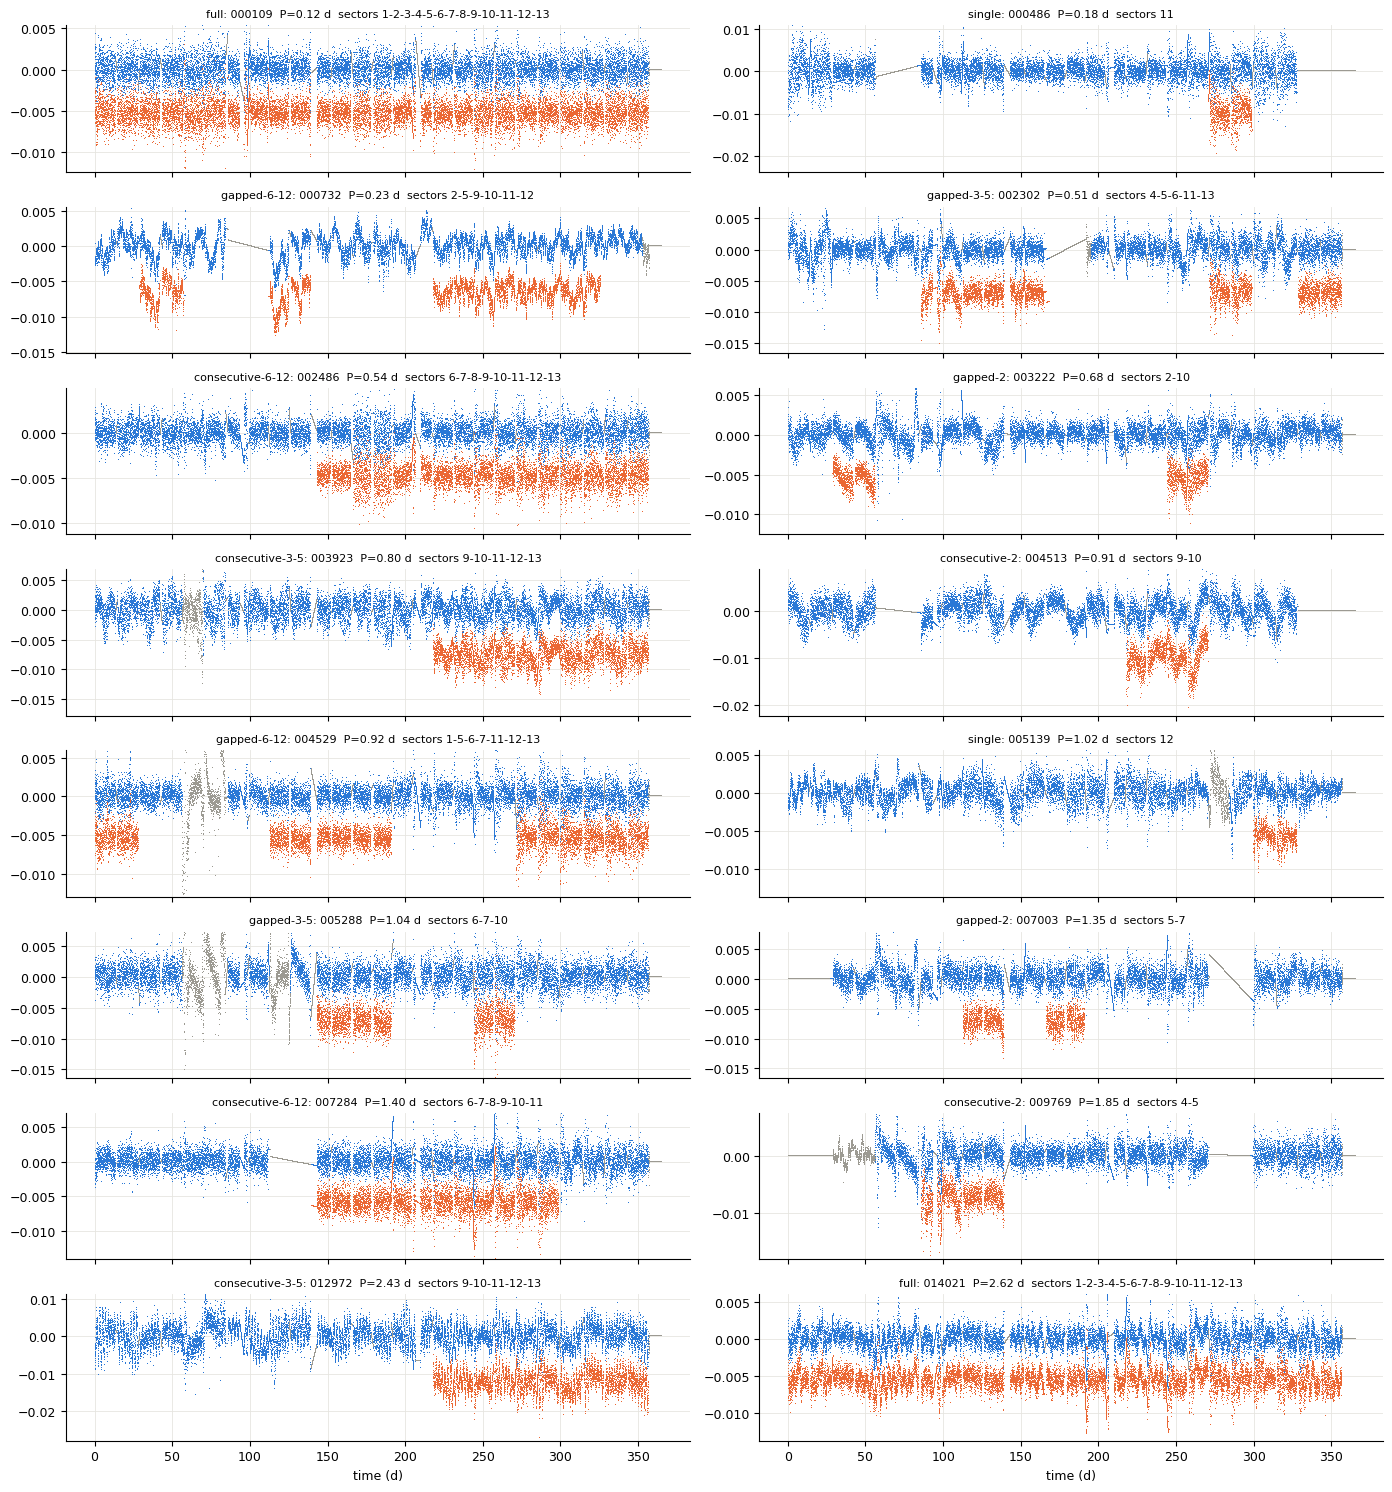

In [12]:
meta = pd.read_csv(D / "example_lcs_meta.csv", dtype={"sectors": str}); Z = np.load(D / "example_lcs.npz")
fig, axs = plt.subplots(8, 2, figsize=(14, 15), sharex=True)
for ax, r in zip(axs.ravel(), meta.itertuples()):
    i = r.i
    ax.plot(Z[f"raw_t_{i}"], Z[f"raw_f_{i}"] - 1, ",", color=GRAY)
    ax.plot(Z[f"full_t_{i}"], Z[f"full_f_{i}"], ",", color=C1)
    off = 4 * np.nanstd(Z[f"full_f_{i}"])
    ax.plot(Z[f"asg_t_{i}"], Z[f"asg_f_{i}"] - off, ",", color=C2)
    lo, hi = np.nanpercentile(Z[f"full_f_{i}"], [0.5, 99.5]); ax.set_ylim(lo - 1.6 * off, hi + 0.3 * off)
    ax.set_title(f"{r.coverage_class}: {r.star_id[-6:]}  P={r.true_period:.2f} d  sectors {r.sectors}", fontsize=8)
for ax in axs[-1]: ax.set_xlabel("time (d)")
fig.tight_layout(); fig.savefig(FIG / "fig_example_lcs.png"); plt.show()

## 7. Failure modes: dev_medium stars at 1–10 d that fail even on the full year

Synthetic stars in these bins succeed at most of the time. Here are six that don't: a random
seeded pick of full-year non-successes in 1–10 d, with their light curve, the ACF, and the
true / measured periods.

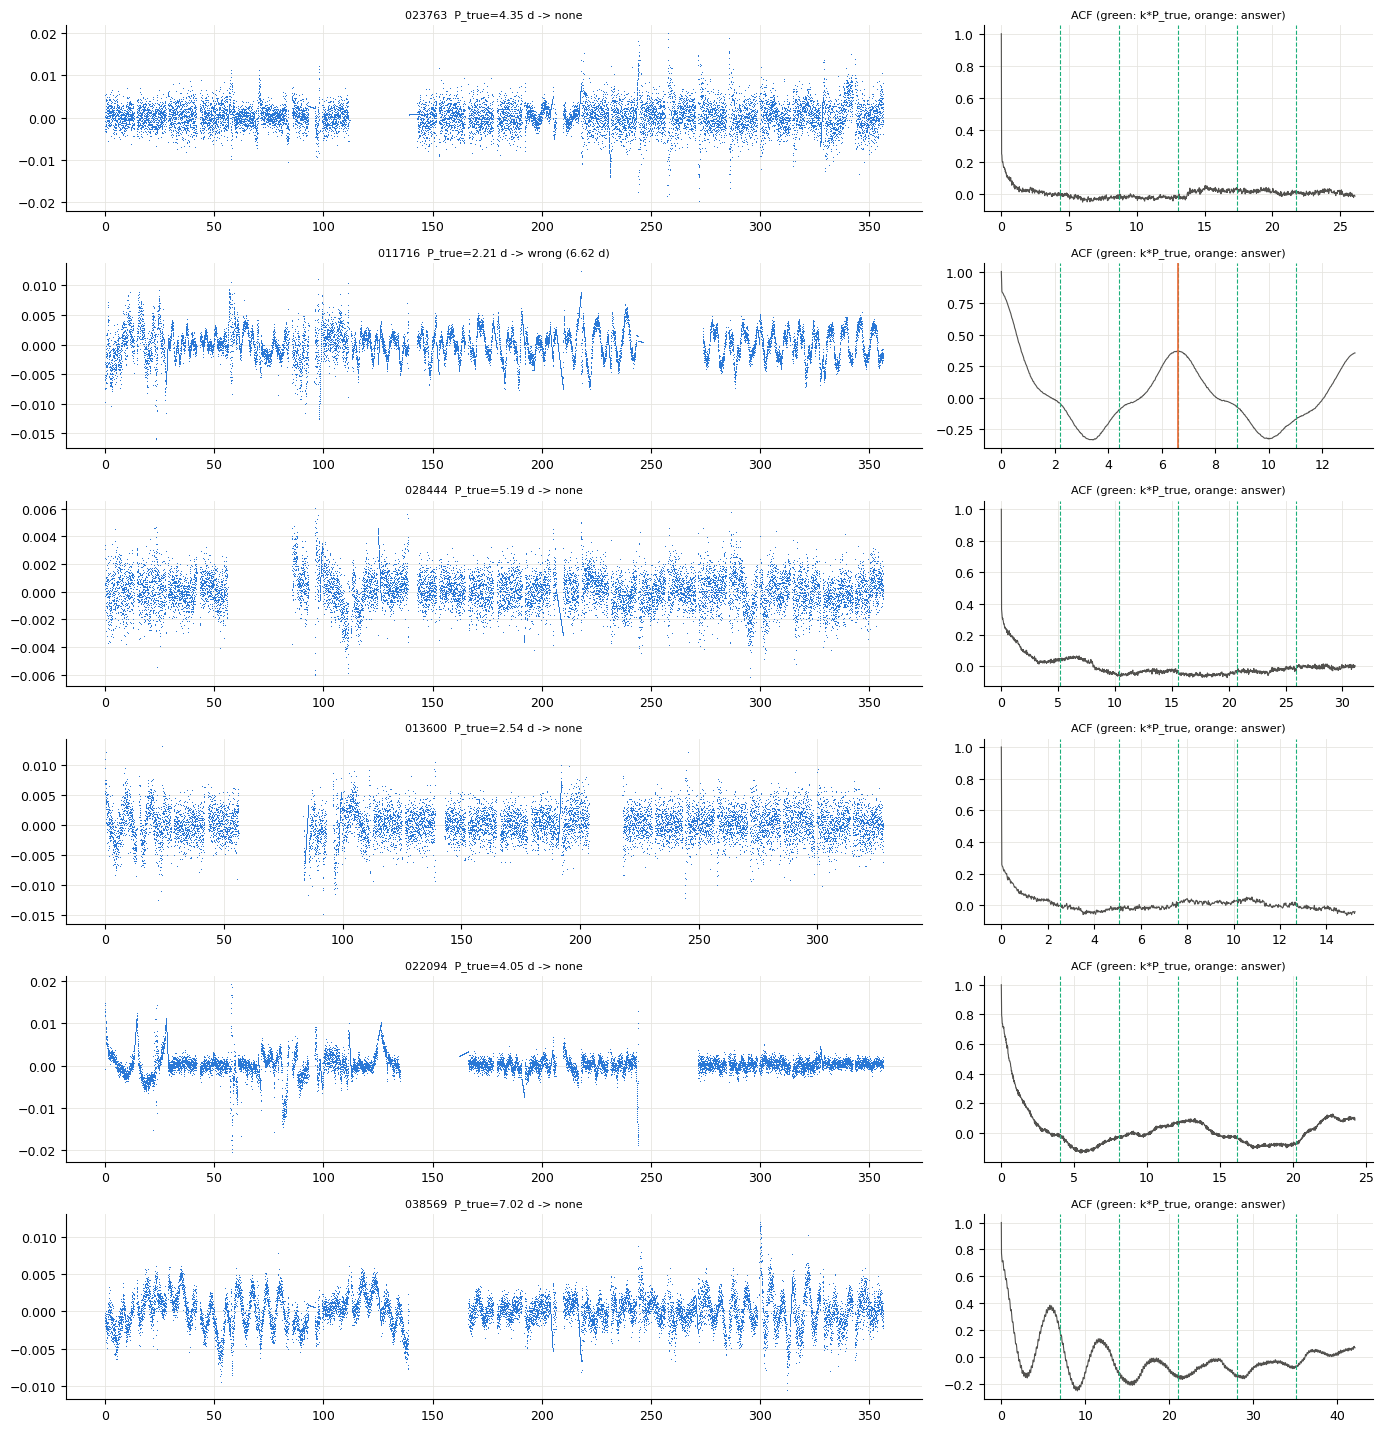

,star_id,true_period,final_outcome,final_period,coverage_class
374,smarts-tess-v1.0-023763,4.3534,none,NaN,consecutive-6-12
278,smarts-tess-v1.0-011716,2.2064,wrong,6.618664,single
393,smarts-tess-v1.0-028444,5.1855,none,NaN,single
305,smarts-tess-v1.0-013600,2.5410,none,NaN,single
365,smarts-tess-v1.0-022094,4.0480,none,NaN,consecutive-2
436,smarts-tess-v1.0-038569,7.0244,none,NaN,single


In [13]:
sys.path.insert(0, str(ROOT / "claude_files"))
from preprocessing import load_smarts_fits
from acf_utils import compute_acf
fm = pf.merge(f[["star_id", "final_period", "true_period", "period_lo", "period_hi"]], on="star_id")
pool6 = fm[fm.pbin.isin(["1-3d", "3-10d"]) & ~fm.final_outcome.isin(["correct", "diffrot"])]
pick = pool6.sample(min(6, len(pool6)), random_state=0)
fig, axs = plt.subplots(len(pick), 2, figsize=(14, 2.4 * len(pick)), gridspec_kw={"width_ratios": [2.2, 1]})
for (a_, b_), r in zip(np.atleast_2d(axs), pick.itertuples()):
    lc = load_smarts_fits(bds.LOCAL_DIR / f"{r.star_id}.fits")
    a_.plot(lc.time, lc.flux, ",", color=C1); a_.set_title(f"{r.star_id[-6:]}  P_true={r.true_period:.2f} d -> {r.final_outcome}"
                                                        + (f" ({r.final_period:.2f} d)" if pd.notna(r.final_period) else ""), fontsize=8)
    lags, acf = compute_acf(lc.time, lc.flux)
    m = lags < 6 * r.true_period
    b_.plot(lags[m], acf[m], color=INK, lw=0.8)
    for k in range(1, 6):
        b_.axvline(k * r.true_period, color=C3, lw=0.8, ls="--")
    if pd.notna(r.final_period):
        b_.axvline(r.final_period, color=C2, lw=1.2)
    b_.set_title("ACF (green: k*P_true, orange: answer)", fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "fig_failure_examples.png"); plt.show()
pick[["star_id", "true_period", "final_outcome", "final_period", "coverage_class"]]